# Fixed detector priors (step1)
The SnowStorm detector priors were not applied in the earlier fits: NNMFit only reads the key `prior`, the config used `priors`.
The fits were re-run with the fixed key (`..._fixedprior`). Here: the previous HESE results, the fit without detector priors
(PassingHESE + _fine combined, as in the earlier `fit_result.ipynb`) and the fit with fixed priors, all SAY; the new SAY vs Poisson
fit; and the 2D (γ, Φ0) scan compared with HESE-7.5.

In [10]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import NNMFit

sys.path.insert(0, "/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks/unblind/step2_hese_flavor_reunblind")
from analysis_utils import (scan_errors, CombinedScan, combine_2d_scans, load_hese75_2d, PREVIOUS_RESULTS,
                            load_triangle_scan, combine_scans, flavor_fractions, latex_comparison_table, PARAMETERS)

plotting_path = "/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks/unblind/step1_hese_flux_reunblind/studies/plots_compare_fixedprior"
os.makedirs(plotting_path, exist_ok=True)

In [11]:
import matplotlib.font_manager as font_manager
font_axis_label = {'family': 'serif',
        'color':  'black',
        'weight': 'normal',
        'size': 22,
        }
font_title = {'family': 'serif',
        'color':  'black',
        'weight': 'bold',
        'size': 20,
        }
font_legend = font_manager.FontProperties(family='serif',
                                   weight='normal',
                                   style='normal', size=13)

plt.rcParams["figure.figsize"] = (6,6)
plt.rcParams.update({'font.family':'serif'})

## 1D scans

In [12]:
data_fits = "/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/dag_scans/flavor_globalfit/hese/unblind/step1_hese_flux_try2/data_fits"
scan = "nbestfit50_all_param_2sigma_1D_10steps_PassingHESE"
drop_unsuccessful = False  # as in fit_result.ipynb
parameters = [p for p in PARAMETERS if p not in ("astro_nue_ratio", "astro_nutau_ratio")]

def load(name):
    return NNMFit.utilities.ScanHandler(f"{data_fits}/{name}", dump=False, drop_unsuccessful=drop_unsuccessful)

# without detector priors: PassingHESE + finer scan combined
wrong_scans = {name: load(name) for name in [scan, f"{scan}_fine"]}
scan_dict = {"wrong": CombinedScan(wrong_scans, {n: s.get_freefit(drop_unsuccessful="True") for n, s in wrong_scans.items()})}
bestfits = {"wrong": scan_dict["wrong"].bestfit}
for name, scan_name in [("SAY", f"{scan}_fixedprior"), ("Poisson", f"{scan}_Poisson_fixedprior")]:
    scan_dict[name] = load(scan_name)
    bestfits[name] = scan_dict[name].get_freefit(drop_unsuccessful="True")

errors = {name: scan_errors(scan_dict[name], bestfits[name], parameters, drop_unsuccessful) for name in scan_dict}
# prompt_norm: profile stays below 1 down to the physical bound 0 -> lower error = distance to 0 (as in fit_result.ipynb)
for name in errors:
    bf, lo, hi = errors[name]["prompt_norm"]
    if np.isnan(lo):
        errors[name]["prompt_norm"] = (bf, bf, hi)

for name, bf in bestfits.items():
    print(f"{name}: freefit llh = {bf['llh']:.4f}")

wrong: freefit llh = 182.0348
SAY: freefit llh = 182.9593
Poisson: freefit llh = 96.1040


In [13]:
def show(columns, parameters):
    df = pd.DataFrame({(name, col): {p: (v[i] if v is not None and v[i] is not None else np.nan) for p, v in res.items()}
                       for name, res in columns.items() for i, col in enumerate(["bestfit", "-1sig", "+1sig"])})
    with pd.option_context("display.float_format", "{:.3f}".format, "display.width", 250, "display.max_columns", 30):
        display(df.reindex(parameters))

## SAY: previous HESE results, without detector priors, with fixed priors

In [14]:
say_columns = {
    "HESE-7.5":             PREVIOUS_RESULTS["HESE-7.5"],
    "HESE-12 flavor":       PREVIOUS_RESULTS["HESE-12 flavor"],
    "no detector priors":   errors["wrong"],
    "fixed priors":         errors["SAY"],
}
show(say_columns, parameters)
print(latex_comparison_table(say_columns,
                             caption=r"Step1 best fit values with $1\sigma$ asymmetric uncertainties (SAY): previous HESE results, "
                                     r"this analysis without the detector priors, and with the detector priors applied.",
                             label="tab:step1_fixedprior", parameters=parameters))

HESE-7.5             HESE-12 flavor             no detector priors             fixed priors            
                       bestfit -1sig +1sig        bestfit -1sig +1sig            bestfit -1sig +1sig      bestfit -1sig +1sig
astro_norm               2.123 0.540 0.487          2.530 1.490 1.780              1.653 0.505 0.852        1.683 0.473 0.497
gamma_astro              2.870 0.190 0.210          2.840 0.180 0.190              2.809 0.174 0.271        2.816 0.170 0.168
conv_norm                1.010 0.340 0.340          0.990 0.200 0.190              1.016 0.191 0.194        1.026 0.189 0.189
prompt_norm              0.000 0.000 5.340          0.000 0.000 2.250              0.843 0.843 2.668        0.994 0.994 2.534
combined_muongun_norm    1.190 0.440 0.450          1.160 0.430 0.420              0.592 0.217 0.242        0.577 0.213 0.250
muongun_asymmetry          NaN   NaN   NaN            NaN   NaN   NaN             -0.042 0.690 0.878       -0.006 0.710 0.951
delta_gamma             -0.053 0.131 0.048         -0.000 1.000 1.000             -0.003 0.049 0.049       -0.003 0.049 0.049
CR_grad                    NaN   NaN   NaN          0.042 1.000 2.000             -0.039 0.961 0.929       -0.093   NaN 0.916
barr_h                     NaN   NaN   NaN          0.000 0.500 0.500              0.001 0.147 0.147        0.002 0.147 0.147
barr_w                     NaN   NaN   NaN          0.000 0.500 0.500              0.005 0.398 0.397        0.011 0.398 0.396
barr_y                     NaN   NaN   NaN          0.000 0.500 0.500              0.034 0.278 0.284        0.051 0.272 0.276
barr_z                     NaN   NaN   NaN          0.000 0.500 0.500              0.021 0.109 0.113        0.030 0.106 0.108
dom_eff                  0.952 0.066 0.093          1.040 0.040 0.060              0.978   NaN 0.059        0.986 0.047 0.046
ice_scat                   NaN   NaN   NaN          0.980 0.040 0.040              0.972   NaN 0.059        0.986 0.036 0.035
ice_abs                    NaN   NaN   NaN          0.990 0.040 0.040              1.005 0.053   NaN        1.003 0.036 0.035
ice_crystal                NaN   NaN   NaN            NaN   NaN   NaN              0.805   NaN 0.126        0.925 0.076 0.070
ice_holep0                 NaN   NaN   NaN         -0.270 0.380 0.280              0.035   NaN 0.213        0.102 0.195 0.168
ice_holep1                 NaN   NaN   NaN         -0.080 0.050 0.040             -0.075   NaN 0.039       -0.065 0.027 0.026

\begin{table}[h]
  \centering
  \caption{Step1 best fit values with $1\sigma$ asymmetric uncertainties (SAY): previous HESE results, this analysis without the detector priors, and with the detector priors applied.}
  \label{tab:step1_fixedprior}
  \begin{tabular}{l r r r r}
    \hline\hline
    Parameter & HESE-7.5 & HESE-12 flavor & no detector priors & fixed priors \\
    \hline
    \hline
    \multicolumn{5}{l}{\textbf{Signal}} \\
    \hline
    $\Phi_{0,\nu_\mu}$ & $2.123^{+0.487}_{-0.540}$ & $2.530^{+1.780}_{-1.490}$ & $1.653^{+0.852}_{-0.505}$ & $1.683^{+0.497}_{-0.473}$ \\
    $\gamma_\mathrm{astro}$ & $2.870^{+0.210}_{-0.190}$ & $2.840^{+0.190}_{-0.180}$ & $2.809^{+0.271}_{-0.174}$ & $2.816^{+0.168}_{-0.170}$ \\
    \hline
    \multicolumn{5}{l}{\textbf{Flux nuisance}} \\
    \hline
    $\Phi_\mathrm{conv}$ & $1.010^{+0.340}_{-0.340}$ & $0.990^{+0.190}_{-0.200}$ & $1.016^{+0.194}_{-0.191}$ & $1.026^{+0.189}_{-0.189}$ \\
    $\Phi_\mathrm{prompt}$ & $0.000^{+5.340}_{-0.000}$ & $

## Fixed priors: SAY vs Poisson

In [15]:
likelihood_columns = {"SAY": errors["SAY"], "Poisson": errors["Poisson"]}
show(likelihood_columns, parameters)
print(latex_comparison_table(likelihood_columns,
                             caption=r"Step1 best fit values with $1\sigma$ asymmetric uncertainties with the detector priors applied, "
                                     r"for the SAY and the Poisson likelihood.",
                             label="tab:step1_fixedprior_SAY_Poisson", parameters=parameters))

SAY             Poisson            
                      bestfit -1sig +1sig bestfit -1sig +1sig
astro_norm              1.683 0.473 0.497   1.682 0.480 0.521
gamma_astro             2.816 0.170 0.168   2.814 0.168 0.166
conv_norm               1.026 0.189 0.189   1.022 0.190 0.189
prompt_norm             0.994 0.994 2.534   1.203 1.203 2.569
combined_muongun_norm   0.577 0.213 0.250   0.817 0.250 0.281
muongun_asymmetry      -0.006 0.710 0.951   0.728 1.184   NaN
delta_gamma            -0.003 0.049 0.049  -0.003 0.049 0.049
CR_grad                -0.093   NaN 0.916  -0.067   NaN 0.920
barr_h                  0.002 0.147 0.147   0.001 0.147 0.147
barr_w                  0.011 0.398 0.396   0.008 0.398 0.396
barr_y                  0.051 0.272 0.276   0.045 0.273 0.278
barr_z                  0.030 0.106 0.108   0.027 0.107 0.109
dom_eff                 0.986 0.047 0.046   0.981 0.054 0.054
ice_scat                0.986 0.036 0.035   0.982 0.040 0.039
ice_abs                 1.003 0.036 0.035   1.004 0.039 0.037
ice_crystal             0.925 0.076 0.070   0.905 0.079 0.081
ice_holep0              0.102 0.195 0.168   0.051   NaN 0.205
ice_holep1             -0.065 0.027 0.026  -0.069 0.032 0.031

\begin{table}[h]
  \centering
  \caption{Step1 best fit values with $1\sigma$ asymmetric uncertainties with the detector priors applied, for the SAY and the Poisson likelihood.}
  \label{tab:step1_fixedprior_SAY_Poisson}
  \begin{tabular}{l r r}
    \hline\hline
    Parameter & SAY & Poisson \\
    \hline
    \hline
    \multicolumn{3}{l}{\textbf{Signal}} \\
    \hline
    $\Phi_{0,\nu_\mu}$ & $1.683^{+0.497}_{-0.473}$ & $1.682^{+0.521}_{-0.480}$ \\
    $\gamma_\mathrm{astro}$ & $2.816^{+0.168}_{-0.170}$ & $2.814^{+0.166}_{-0.168}$ \\
    \hline
    \multicolumn{3}{l}{\textbf{Flux nuisance}} \\
    \hline
    $\Phi_\mathrm{conv}$ & $1.026^{+0.189}_{-0.189}$ & $1.022^{+0.189}_{-0.190}$ \\
    $\Phi_\mathrm{prompt}$ & $0.994^{+2.534}_{-0.994}$ & $1.203^{+2.569}_{-1.203}$ \\
    $\Phi_\mathrm{muon}$ & $0.577^{+0.250}_{-0.213}$ & $0.817^{+0.281}_{-0.250}$ \\
    $a_\mathrm{muon}$ & $-0.006^{+0.951}_{-0.710}$ & $0.728^{---}_{-1.184}$ \\
    $\Delta\gamma_{\rm CR}$ & $-0.003^{+0.049}_{-0.049

## 2D scan (γ, Φ0)
Without detector priors: the three rounds of the 2D scan combined (lowest llh per grid point, as in `fit_result_2D.ipynb`).

In [16]:
data_fits_2D = "/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/dag_scans/flavor_globalfit/hese/unblind/step1_hese_flux_try2/data_fits_2D"
scan_2d = "nbestfit20_gamma_norm_larger_range_2D_225steps"
x_param, y_param = "gamma_astro", "astro_norm"

def load_2d(names):
    """combined 2D scan of several rounds: (x, y, dllh, bestfit), dllh relative to the lowest freefit llh"""
    scans = {n: NNMFit.utilities.ScanHandler(f"{data_fits_2D}/{n}", dump=False, drop_unsuccessful=True) for n in names}
    freefits = {n: s.get_freefit(drop_unsuccessful=True) for n, s in scans.items()}
    best = min(freefits, key=lambda n: freefits[n]["llh"])
    xyd = [scans[n].get_scan_xydllh(x=x_param, y=y_param, dllh_ref=freefits[best]["llh"], interpolate=True, drop_unsuccessful=True)
           for n in names]
    x, y, dllh = combine_2d_scans(*zip(*xyd))
    return x, y, dllh, freefits[best]

scans_2d = {
    "SAY, no detector priors":   load_2d([scan_2d, f"{scan_2d}_round2", f"{scan_2d}_round3"]),
    "SAY, fixed priors":         load_2d([f"{scan_2d}_fixedprior"]),
    "Poisson, fixed priors":     load_2d([f"{scan_2d}_Poisson_fixedprior"]),
}
G_hese, N_hese, Z_hese, hese_levels, hese_bf = load_hese75_2d()
for name, (x, y, dllh, bf) in scans_2d.items():
    print(f"{name}: gamma = {bf[x_param]:.3f}, phi0 = {bf[y_param]:.3f}, llh = {bf['llh']:.4f}, NaN grid points: {np.isnan(dllh).sum()}")

SAY, no detector priors: gamma = 2.809, phi0 = 1.653, llh = 182.0348, NaN grid points: 0
SAY, fixed priors: gamma = 2.816, phi0 = 1.683, llh = 182.9593, NaN grid points: 0
Poisson, fixed priors: gamma = 2.814, phi0 = 1.682, llh = 96.1040, NaN grid points: 0


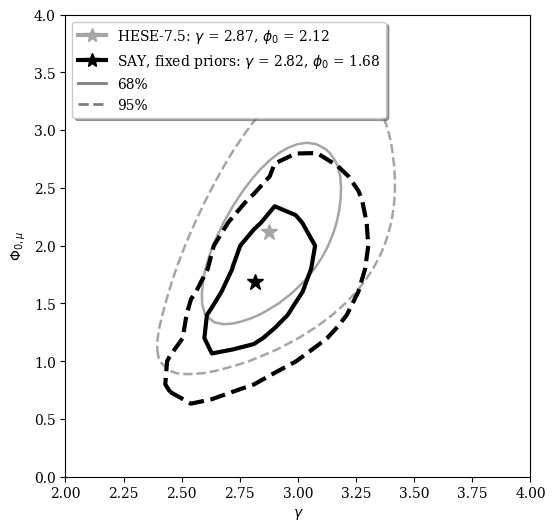

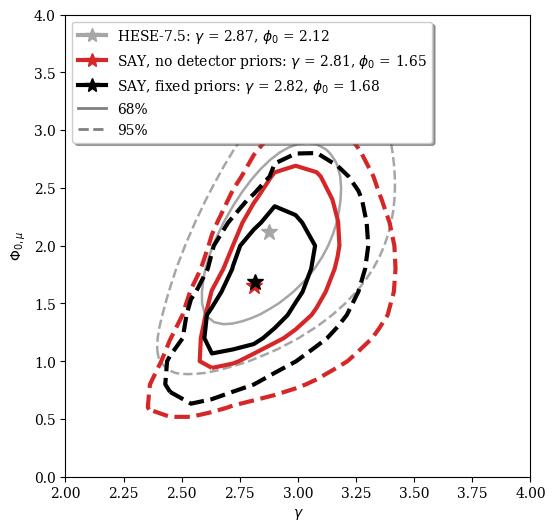

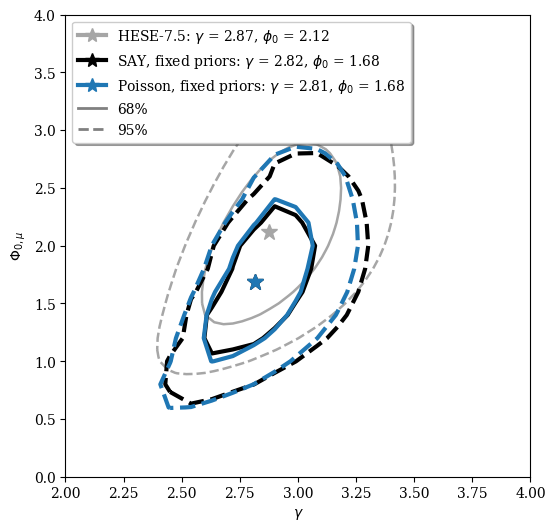

In [17]:
HESE_COLOR = "0.65"  # light grey: HESE-7.5 drawn in the background

def plot_2d(names, colors, savepath):
    lw, linestyles, our_levels = 3.0, ["-", "--"], [2.27, 5.99]  # 68%, 95% (as in fit_result_2D.ipynb)
    fig, ax = plt.subplots(1, 1)
    lh, ll = [], []
    for name, color in zip(names, colors):
        if name == "HESE-7.5":
            # previous result in the background
            color = HESE_COLOR
            ax.contour(G_hese, N_hese, Z_hese, levels=hese_levels, colors=color, linewidths=0.6 * lw, linestyles=linestyles)
            bfx, bfy = hese_bf
        else:
            x, y, dllh, bf = scans_2d[name]
            ax.contour(x, y, dllh, levels=our_levels, colors=color, linewidths=lw, linestyles=linestyles)
            bfx, bfy = bf[x_param], bf[y_param]
        ax.plot([bfx], [bfy], "*", color=color, markersize=12)
        lh.append(Line2D([0], [0], color=color, linewidth=lw, marker="*", markersize=10))
        ll.append(f"{name}: " + r"$\gamma$ = " + f"{bfx:.2f}, " + r"$\phi_0$ = " + f"{bfy:.2f}")
    lh += [Line2D([0], [0], color="grey", linestyle=ls, linewidth=2) for ls in linestyles]
    ll += ["68%", "95%"]
    ax.set_xlabel(r"$\gamma$")
    ax.set_ylabel(r"$\Phi_{0,\mu}$")
    ax.legend(lh, ll, loc="upper left", frameon=True, fancybox=True, shadow=True, fontsize=10)
    fig.savefig(savepath, bbox_inches="tight")
    fig.savefig(savepath.replace(".pdf", ".png"), bbox_inches="tight", dpi=100)
    plt.show()

plot_2d(["HESE-7.5", "SAY, fixed priors"], [HESE_COLOR, "black"], f"{plotting_path}/contour_fixedprior_vs_hese7.5.pdf")
plot_2d(["HESE-7.5", "SAY, no detector priors", "SAY, fixed priors"], [HESE_COLOR, "C3", "black"], f"{plotting_path}/contour_hese7.5_wrong_fixedprior.pdf")
plot_2d(["HESE-7.5", "SAY, fixed priors", "Poisson, fixed priors"], [HESE_COLOR, "black", "C0"], f"{plotting_path}/contour_fixedprior_SAY_vs_Poisson.pdf")